# Grouped training curves

Thin driver for `analytics.training.plot_models_together`. Edit config cells only; plotting logic lives in the library module.


In [1]:
import sys
from pathlib import Path

# Add src/ to sys.path before importing analytics (required for Jupyter kernels).
_project_root = Path.cwd().resolve()
while _project_root != _project_root.parent and not (_project_root / "src" / "analytics").is_dir():
    _project_root = _project_root.parent
if not (_project_root / "src" / "analytics").is_dir():
    raise FileNotFoundError(
        "Could not find the project root (expected src/analytics/). "
        "Set the notebook working directory to the QB-PIER repo root."
    )
_src = _project_root / "src"
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))

from analytics.notebook_setup import notebook_paths, load_all_metrics

project_root, TRAINING_ROOT, ATTACK_EXPERIMENT_DIR, OUT, _src = notebook_paths("grouped_curves", start=_project_root)


In [2]:
from pathlib import Path
from loading import crawl_experiments, load_metrics

model_dirs = [Path(p) for p in crawl_experiments(str(TRAINING_ROOT))]
print(f"models found: {len(model_dirs)}")


models found: 51


In [3]:
models = load_all_metrics(model_dirs, load_metrics)
print(f"loaded metrics for {len(models)} models")


Error loading metrics: Metrics file not found at C:\Users\fwilh\Desktop\QB-PIER\logs\ByModel\Quantum\vqm\n_qdepth=200,ansatz=strong\0\metrics\logger.pkl
Traceback (most recent call last):
  File "C:\Users\fwilh\Desktop\QB-PIER\src\metrics\MetricsContainer.py", line 182, in load_metrics
    raise FileNotFoundError(f"Metrics file not found at {pkl_path}")
FileNotFoundError: Metrics file not found at C:\Users\fwilh\Desktop\QB-PIER\logs\ByModel\Quantum\vqm\n_qdepth=200,ansatz=strong\0\metrics\logger.pkl


loaded metrics for 51 models


In [ ]:
keyword = "ansatz=random"  # choose the keyword you want to filter by

subset_by_keyword = {k: v for k, v in models.items() if keyword in k}
print(f"found {len(subset_by_keyword)} models with keyword {keyword!r}")
subset_by_keyword

found 11 models with keyword 'ansatz=random'


{'C:\\Users\\fwilh\\Desktop\\QB-PIER\\logs\\ByModel\\Hybrid\\hquanv\\n_qdepth=100,ansatz=random': {0: <metrics.MetricsContainer.MetricsContainer at 0x1caa73cb750>,
  42: <metrics.MetricsContainer.MetricsContainer at 0x1caa740e790>},
 'C:\\Users\\fwilh\\Desktop\\QB-PIER\\logs\\ByModel\\Hybrid\\hquanv\\n_qdepth=50,ansatz=random': {0: <metrics.MetricsContainer.MetricsContainer at 0x1caa740fbd0>,
  42: <metrics.MetricsContainer.MetricsContainer at 0x1caa7445e90>},
 'C:\\Users\\fwilh\\Desktop\\QB-PIER\\logs\\ByModel\\Hybrid\\hvql\\ansatz=random,qdepth=50': {0: <metrics.MetricsContainer.MetricsContainer at 0x1caa7447210>,
  42: <metrics.MetricsContainer.MetricsContainer at 0x1caa7489e10>},
 'C:\\Users\\fwilh\\Desktop\\QB-PIER\\logs\\ByModel\\Hybrid\\hvqm\\ansatz=random,qdepth=50': {0: <metrics.MetricsContainer.MetricsContainer at 0x1caa74cbd10>,
  42: <metrics.MetricsContainer.MetricsContainer at 0x1caa7502d90>},
 'C:\\Users\\fwilh\\Desktop\\QB-PIER\\logs\\ByModel\\Quantum\\vqm\\n_qdepth=10,

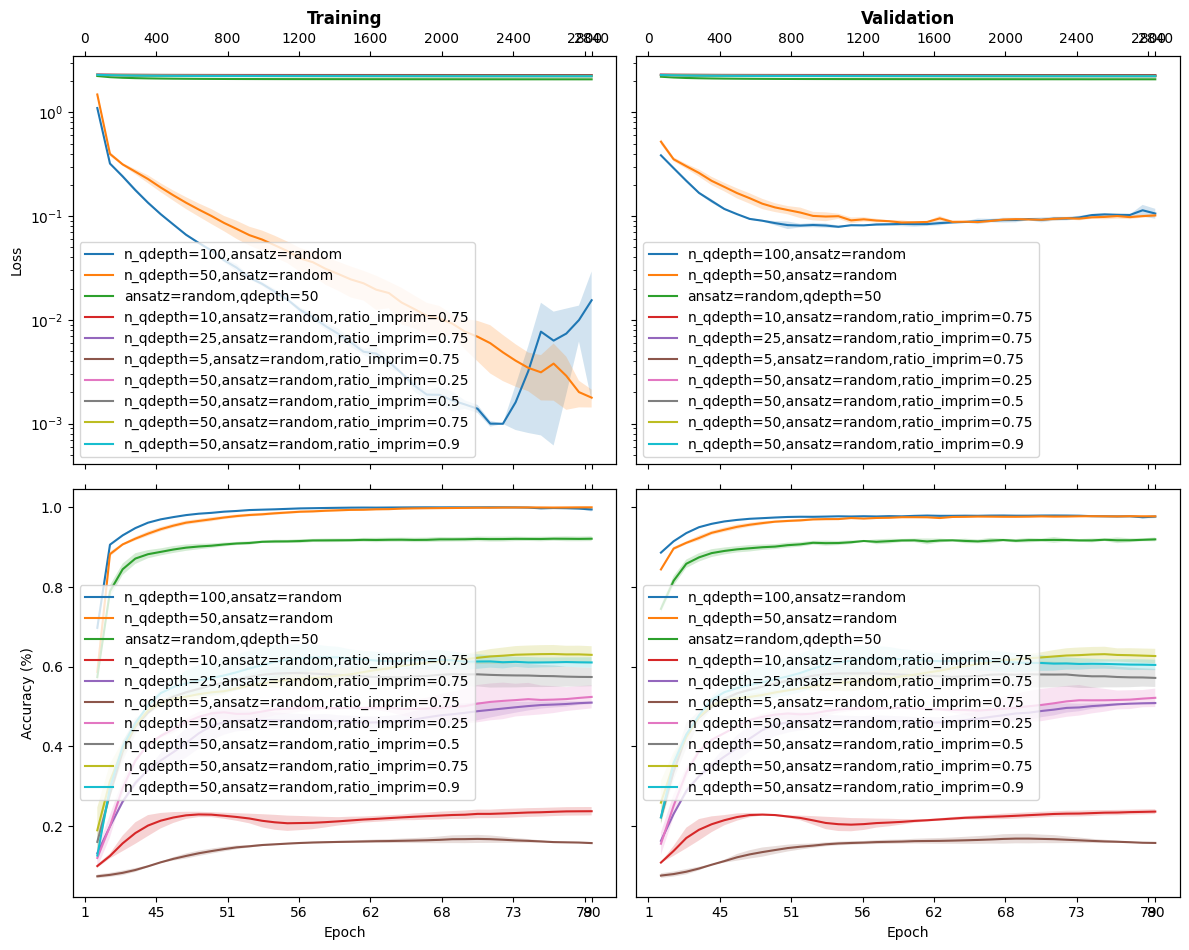

In [18]:
from analytics.training import plot_models_together

subset = {Path(k).name: v for k, v in list(subset_by_keyword.items())}
plot_models_together(subset, fig_dir=str(OUT), show=True)
